In [1]:
# Import modules 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
# This is the EPA AQS hourly NO2 file. 42602 is the AQS parameter code for NO2.
epa_file = Path("hourly_42602_2023.csv")

start_dt = pd.Timestamp("2023-07-01 00:00")
end_dt   = pd.Timestamp("2023-07-31 23:00")

In [3]:
# low_memory=False keeps pandas from guessing mixed column types in chunks.
no2 = pd.read_csv(epa_file, low_memory=False)

# I like replacing underscores so the column names match the format I usually use.
no2.columns = [c.replace("_", " ") for c in no2.columns]

# Quick check of what we loaded.
print("Rows loaded:", len(no2))
print("Columns:")
print(no2.columns.tolist())

Rows loaded: 3595761
Columns:
['State Code', 'County Code', 'Site Num', 'Parameter Code', 'POC', 'Latitude', 'Longitude', 'Datum', 'Parameter Name', 'Date Local', 'Time Local', 'Date GMT', 'Time GMT', 'Sample Measurement', 'Units of Measure', 'MDL', 'Uncertainty', 'Qualifier', 'Method Type', 'Method Code', 'Method Name', 'State Name', 'County Name', 'Date of Last Change']


In [4]:
# AQS files usually store date and time separately in GMT.
no2["Datetime GMT"] = pd.to_datetime(
    no2["Date GMT"] + " " + no2["Time GMT"],
    errors="coerce"
)

# Keep only July 2023.
no2_july = no2[
    (no2["Datetime GMT"] >= start_dt) &
    (no2["Datetime GMT"] <= end_dt)
].copy()

print("Rows in July:", len(no2_july))
print("Date range:", no2_july["Datetime GMT"].min(), "to", no2_july["Datetime GMT"].max())

Rows in July: 304022
Date range: 2023-07-01 00:00:00 to 2023-07-31 23:00:00


In [5]:
# First I want to know if there are missing values in the columns I need.
qaqc_cols = [
    "Datetime GMT",
    "Sample Measurement",
    "Units of Measure",
    "Latitude",
    "Longitude",
    "State Code",
    "County Code",
    "Site Num",
]

print("\nMissing values in key columns:")
print(no2_july[qaqc_cols].isna().sum())

# Check the reported units.
print("\nUnits in file:")
print(no2_july["Units of Measure"].value_counts(dropna=False))

# Convert ppm to ppb if needed so everything is easier to interpret.
# NO2 is usually discussed in ppb.
no2_july["NO2_ppb"] = no2_july["Sample Measurement"]

ppm_mask = no2_july["Units of Measure"].str.contains("Parts per million", na=False)
no2_july.loc[ppm_mask, "NO2_ppb"] = no2_july.loc[ppm_mask, "Sample Measurement"] * 1000

# Flag values that look suspicious.
# I am not deleting these yet; I just want to see what might need review.
no2_july["flag_negative"] = no2_july["NO2_ppb"] < 0
no2_july["flag_high"] = no2_july["NO2_ppb"] > 200

print("\nQAQC flags:")
print("Negative NO2 values:", no2_july["flag_negative"].sum())
print("NO2 values > 200 ppb:", no2_july["flag_high"].sum())

# For plotting, remove missing, negative, and very high values.
# This keeps the plot readable while preserving the original dataframe above.
no2_clean = no2_july[
    no2_july["NO2_ppb"].notna() &
    (~no2_july["flag_negative"]) &
    (~no2_july["flag_high"])
].copy()

print("\nRows after basic QAQC:", len(no2_clean))



Missing values in key columns:
Datetime GMT          0
Sample Measurement    0
Units of Measure      0
Latitude              0
Longitude             0
State Code            0
County Code           0
Site Num              0
dtype: int64

Units in file:
Parts per billion    304022
Name: Units of Measure, dtype: int64

QAQC flags:
Negative NO2 values: 3762
NO2 values > 200 ppb: 0

Rows after basic QAQC: 300260


In [6]:
# Create a monitor ID so each site is easier to track.
no2_clean["monitor_id"] = (
    no2_clean["State Code"].astype(str).str.zfill(2) + "-" +
    no2_clean["County Code"].astype(str).str.zfill(3) + "-" +
    no2_clean["Site Num"].astype(str).str.zfill(4)
)

monitor_summary = (
    no2_clean
    .groupby(["monitor_id", "Latitude", "Longitude"], as_index=False)
    .agg(
        n_hours=("NO2_ppb", "count"),
        mean_no2=("NO2_ppb", "mean"),
        max_no2=("NO2_ppb", "max")
    )
    .sort_values("n_hours", ascending=False)
)

print("\nMonitor summary:")
display(monitor_summary)


Monitor summary:


,monitor_id,Latitude,Longitude,n_hours,mean_no2,max_no2
63,06-065-8001,33.999580,-117.416010,1488,9.807191,44.9
42,06-037-1103,34.066590,-118.226880,1482,13.264035,48.0
377,49-011-0004,40.902967,-111.884467,1473,5.779362,35.7
383,49-035-3006,40.736389,-111.872222,1473,4.931161,23.3
211,27-003-1002,45.137680,-93.207615,1457,5.050652,27.0
...,...,...,...,...,...,...
351,48-201-1050,29.583047,-95.015544,99,2.297980,6.8
17,06-001-0013,37.864767,-122.302741,94,6.744681,17.3
91,06-083-1013,34.725352,-120.428717,83,0.220482,2.1
115,08-067-1004,37.303890,-107.484167,73,0.267123,1.1


In [7]:
# I am using downtown Chicago as a reference point and picking the closest monitor
# with enough hourly observations in July.
chicago_lat = 41.8781
chicago_lon = -87.6298

monitor_summary["distance_to_chicago"] = np.sqrt(
    (monitor_summary["Latitude"] - chicago_lat)**2 +
    (monitor_summary["Longitude"] - chicago_lon)**2
)

# Require at least 24 hours of observations so the selected monitor has enough data.
candidate_monitors = monitor_summary[monitor_summary["n_hours"] >= 24].copy()

selected_monitor = (
    candidate_monitors
    .sort_values("distance_to_chicago")
    .iloc[0]
)

selected_id = selected_monitor["monitor_id"]

print("\nSelected monitor:")
print(selected_monitor)


Selected monitor:
monitor_id             17-031-0219
Latitude                 41.920009
Longitude               -87.672995
n_hours                        487
mean_no2                 19.103491
max_no2                       60.8
distance_to_chicago       0.060184
Name: 148, dtype: object


<h1> Plot 1 day 


Rows for selected day: 24


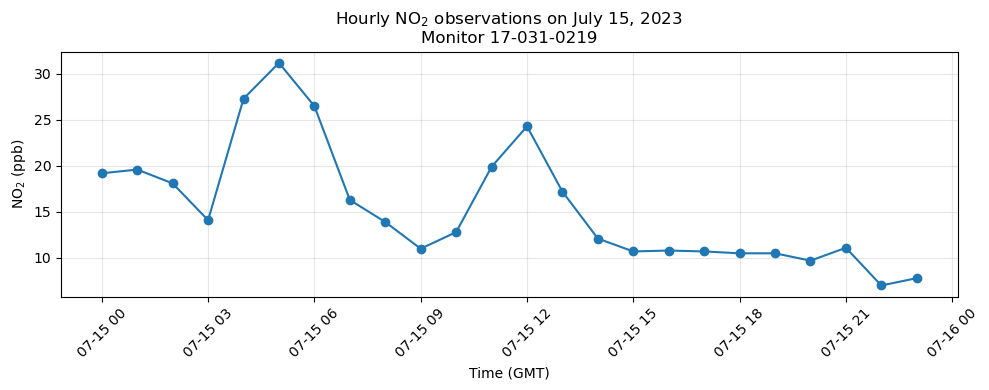

In [8]:
# Pick one day to look at closely.
plot_day = pd.Timestamp("2023-07-15")

one_day = no2_clean[
    (no2_clean["monitor_id"] == selected_id) &
    (no2_clean["Datetime GMT"] >= plot_day) &
    (no2_clean["Datetime GMT"] < plot_day + pd.Timedelta(days=1))
].copy()

one_day = one_day.sort_values("Datetime GMT")

print("\nRows for selected day:", len(one_day))

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    one_day["Datetime GMT"],
    one_day["NO2_ppb"],
    marker="o",
    linewidth=1.5
)

ax.set_title(f"Hourly NO$_2$ observations on {plot_day:%B %d, %Y}\nMonitor {selected_id}")
ax.set_xlabel("Time (GMT)")
ax.set_ylabel("NO$_2$ (ppb)")
ax.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<h1> Plot All July Observations for one station

In [9]:
# Keep only the monitor selected in the previous section.
monitor_data = no2_clean[
    no2_clean["monitor_id"] == selected_id
].copy()

# Sort the data by time before plotting.
monitor_data = monitor_data.sort_values("Datetime GMT")

# Create a continuous hourly time index covering all of July.
# This helps identify any missing hours in the observations.
hourly_index = pd.date_range(
    start=start_dt,
    end=end_dt,
    freq="H"
)

# Calculate the average NO2 concentration for each hour.
# Most monitors only report one value each hour, but averaging
# makes the code more robust in case duplicate observations exist.
hourly_no2 = (
    monitor_data
    .groupby("Datetime GMT")["NO2_ppb"]
    .mean()
    .reindex(hourly_index)
)

# Count how many hourly observations are missing.
print(f"Expected hours in July: {len(hourly_index)}")
print(f"Observed hours: {hourly_no2.notna().sum()}")
print(f"Missing hours: {hourly_no2.isna().sum()}")


Expected hours in July: 744
Observed hours: 487
Missing hours: 257


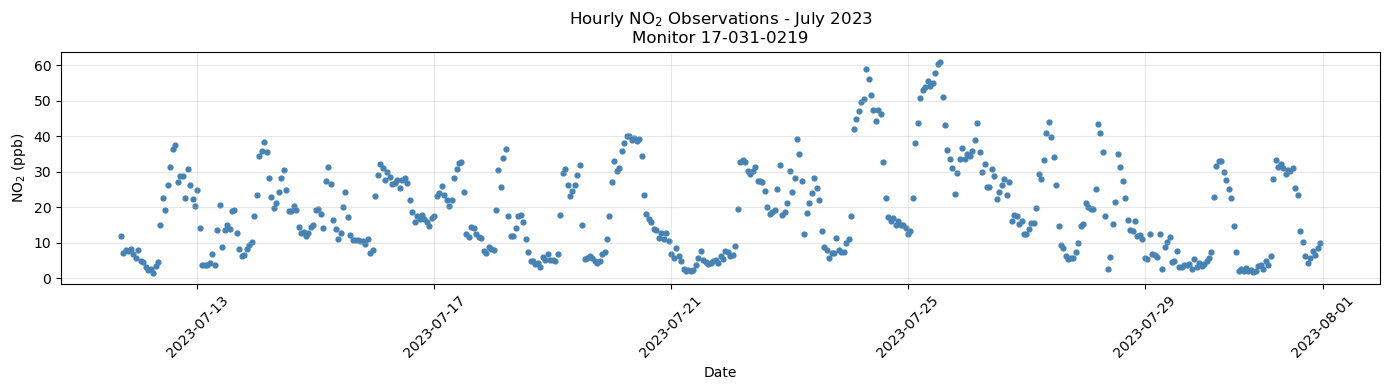

In [11]:
fig, ax = plt.subplots(figsize=(14, 4))

ax.scatter(
    hourly_no2.index,
    hourly_no2.values,
    s=12,
    color="steelblue"
)

ax.set_title(f"Hourly NO$_2$ Observations - July 2023\nMonitor {selected_id}")
ax.set_xlabel("Date")
ax.set_ylabel("NO$_2$ (ppb)")

ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


<h3> Scatter plots allow you to see missing data, whereas the line plots make it harder to visually see when observations are not available. Something to keep in mind when visualizing observed data. 

<h1> Plot the average July diurnal cycle 

In [12]:
# Keep only the selected monitor.
monitor_data = no2_clean[
    no2_clean["monitor_id"] == selected_id
].copy()

# Extract the hour of day (0-23).
monitor_data["Hour"] = monitor_data["Datetime GMT"].dt.hour

# Calculate the average NO2 concentration for each hour.
hourly_mean = (
    monitor_data
    .groupby("Hour")["NO2_ppb"]
    .mean()
)

# Also calculate the standard deviation to understand variability.
hourly_std = (
    monitor_data
    .groupby("Hour")["NO2_ppb"]
    .std()
)

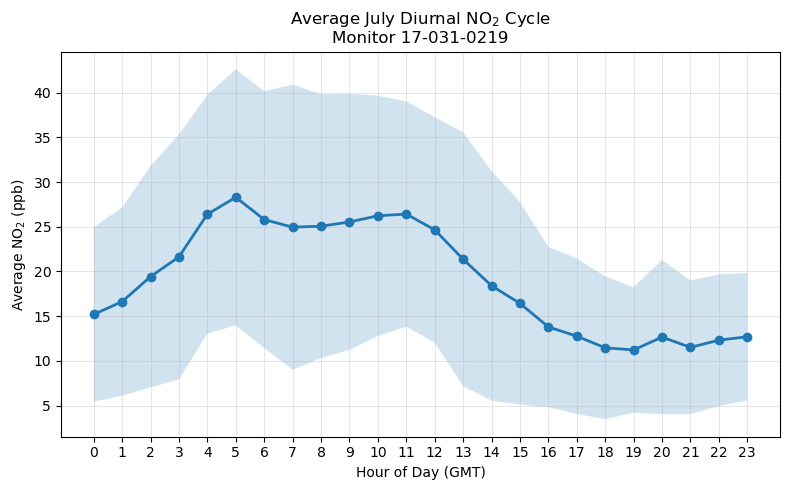

In [14]:
fig, ax = plt.subplots(figsize=(8,5))

ax.plot(
    hourly_mean.index,
    hourly_mean.values,
    marker="o",
    linewidth=2
)

# Optional: show ±1 standard deviation
ax.fill_between(
    hourly_mean.index,
    hourly_mean - hourly_std,
    hourly_mean + hourly_std,
    alpha=0.2
)

ax.set_xticks(range(24))
ax.set_xlabel("Hour of Day (GMT)")
ax.set_ylabel("Average NO$_2$ (ppb)")
ax.set_title(f"Average July Diurnal NO$_2$ Cycle\nMonitor {selected_id}")

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

<h3> Note when NO2 is the highest and lowest during the day. 

In [15]:
# Print out the stats that are visualized above. 
hourly_stats = (
    monitor_data
    .groupby("Hour")["NO2_ppb"]
    .agg(["mean", "std", "count"])
)

display(hourly_stats)

,mean,std,count
Hour,,,
0,15.200000,9.756995,20
1,16.630000,10.537057,20
2,19.430000,12.389219,20
3,21.635000,13.713047,20
4,26.405000,13.353079,20
5,28.305000,14.324821,20
6,25.810000,14.371533,20
7,24.955000,15.949607,20
8,25.070000,14.761547,20
